# 01 — Exploratory data analysis
Synthetic parallel-run data for the Parallel-Run Reconciler. **All data is synthetic** — deals, ledger accounts and feed statistics are generated with injected causes so the models can be evaluated against known truth.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from src.generate_data import generate
from src.generate_ledger import generate_ledger
from src.feed_health import generate_feed

deals = generate(6000, seed=42)
deals.head(8)

,deal_id,close_month,close_date,plan,amount_old,amount_new,old_commission,new_commission,crosses_period,cause,cause_secondary
0,D-00035,1,2026-01-03,Strategic,20311.57,20311.57,812.46,812.46,0,none,
1,D-00044,1,2026-01-17,Tiered,4487.50,4487.50,269.25,269.25,0,none,
2,D-00055,1,2026-01-25,Standard,5030.04,5030.04,251.50,251.50,0,none,
3,D-00068,1,2026-01-05,Standard,31892.11,31892.11,1594.61,1594.61,0,none,
4,D-00103,1,2026-01-03,Strategic,3168.00,3168.00,126.72,126.72,0,none,
5,D-00116,1,2026-01-24,Standard,9070.11,9070.11,453.51,453.51,0,none,
6,D-00126,1,2026-01-05,Standard,7019.68,7019.68,350.98,350.98,0,none,
7,D-00137,1,2026-01-21,Standard,21780.96,21780.96,1089.05,0.00,1,timing,


In [3]:
deals.describe().round(2)

,close_month,amount_old,amount_new,old_commission,new_commission,crosses_period
count,6000.00,6000.00,5945.00,6000.00,6000.00,6000.00
mean,6.49,13807.16,13798.04,707.36,666.64,0.15
std,3.46,12641.41,12603.86,662.89,650.93,0.36
min,1.00,441.31,441.31,22.07,0.00,0.00
25%,3.00,5892.86,5892.16,297.76,265.85,0.00
50%,6.00,9896.39,9892.11,501.05,477.06,0.00
75%,10.00,17078.16,17075.18,884.87,838.00,0.00
max,12.00,128052.34,128052.34,7683.14,7683.14,1.00


## Cause mix
82% of deals agree exactly (`none`). The reviewer's workload is the other ~18%, split across four injected causes. ~5% of differing deals carry a second, overlapping cause (`cause_secondary`) — the hard case.

cause
none        4930
rounding     362
rule         282
timing       224
data         202
Name: count, dtype: int64

dual-cause rows: 54


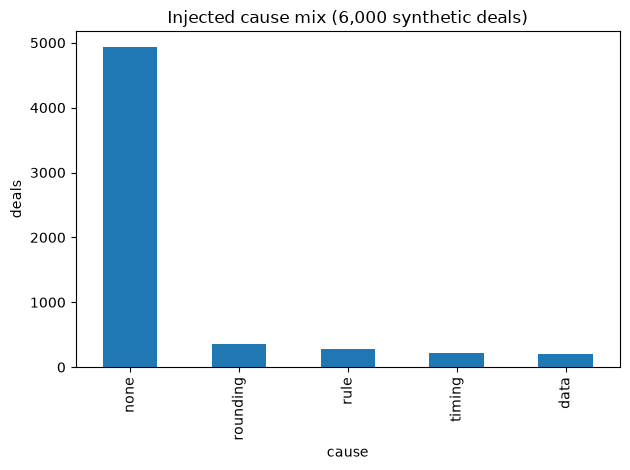

In [4]:
counts = deals["cause"].value_counts()
dual = int((deals["cause_secondary"] != "").sum())
print(counts)
print(f"\ndual-cause rows: {dual}")
counts.plot.bar(title="Injected cause mix (6,000 synthetic deals)")
plt.ylabel("deals"); plt.tight_layout()

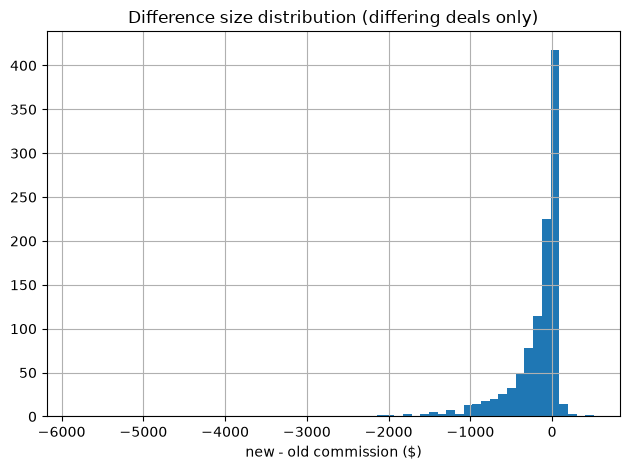

In [5]:
diffs = deals[deals["new_commission"] != deals["old_commission"]]
diffs.assign(diff=(diffs["new_commission"] - diffs["old_commission"]))["diff"].hist(bins=60)
plt.title("Difference size distribution (differing deals only)")
plt.xlabel("new - old commission ($)"); plt.tight_layout()

deals crossing a period boundary: 929
deals missing from the new system: 55


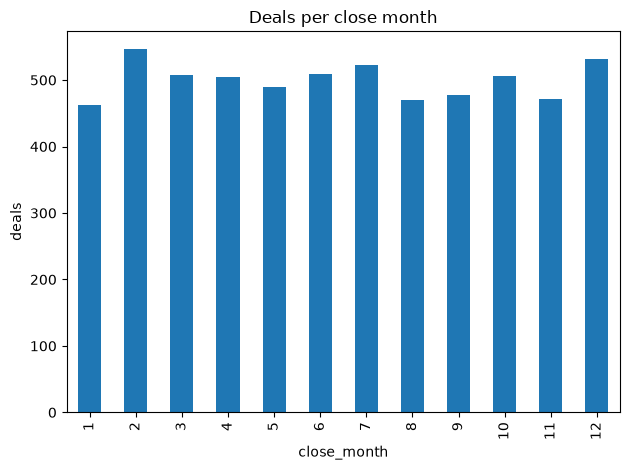

In [6]:
print("deals crossing a period boundary:", int(deals["crosses_period"].sum()))
print("deals missing from the new system:", int(deals["amount_new"].isna().sum()))
deals.groupby("close_month").size().plot.bar(title="Deals per close month")
plt.ylabel("deals"); plt.tight_layout()

## The other two problems, at a glance

In [7]:
ledger = generate_ledger(seed=42)
print(f"{len(ledger)} accounts, {int(ledger['is_mismapped'].sum())} injected mis-mappings")
ledger[["account_name", "category", "entity", "old_code", "mapped_new_code", "old_balance", "new_balance", "is_mismapped"]].head(6)

160 accounts, 20 injected mis-mappings


,account_name,category,entity,old_code,mapped_new_code,old_balance,new_balance,is_mismapped
0,Product Revenue,Revenue,US,4100-US,40100-US,224435.02,328949.91,0
1,Service Revenue,Revenue,US,4110-US,40110-US,190478.20,190498.04,0
2,Subscription Revenue,Revenue,US,4120-US,40120-US,246989.63,246845.10,0
3,Professional Services Revenue,Revenue,US,4130-US,60110-US,201552.73,201504.91,1
4,Other Income,Revenue,US,4140-US,40100-US,104275.76,328949.91,1
5,Licensing Revenue,Revenue,US,4150-US,40150-US,286984.71,286819.52,0


In [8]:
feed = generate_feed(seed=42)
feed[["month", "rows_expected", "rows_received", "null_rate", "late_arrivals", "health_score", "status"]]

,month,rows_expected,rows_received,null_rate,late_arrivals,health_score,status
0,2025-01,51154,50984,0.0058,450,93.836657,healthy
1,2025-02,51082,50465,0.0020,195,97.095673,healthy
2,2025-03,52565,52145,0.0024,129,97.229513,healthy
3,2025-04,52858,52100,0.0011,221,97.623305,healthy
4,2025-05,52211,51549,0.0065,224,93.387434,healthy
5,2025-06,54732,54472,0.0057,397,94.061753,healthy
6,2025-07,54922,30207,0.0059,353,66.526986,break
7,2025-08,55636,55609,0.0065,460,93.530076,healthy
8,2025-09,54839,54284,0.0042,397,94.935760,healthy
9,2025-10,56223,55692,0.0050,292,94.646860,healthy


**Takeaways.** The signal structure is deliberately realistic, not random: rounding differences are cent-level, timing differences zero out the new commission on boundary-crossing deals, data differences change the amount (or delete the deal), and rule differences scale with deal size. Dual-cause rows break every one of those clean patterns — which is exactly why the production design is rules-first with an ML second opinion.